In [12]:
%matplotlib inline
from matplotlib import rcParams

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Introduction to clustering

Clustering is a machine learning technique used to group unlabeled datapoints in groups called *clusters*. The grouping is done such that similar items are together in the same cluster and items in different clusters are dissimilar from each-other. Typically similarity is defined using a distance measure (Euclidean, cosine, etc). Common practical applications for clustering include: market segmentation, social network analysis, search result grouping, anomaly detection etc.


Two clustering methods will be explored in this notebook:

- K-means.
- Hierarchical clustering.

More methods can be found [here](https://scikit-learn.org/stable/modules/classes.html?highlight=cluster#module-sklearn.cluster).


#### Resources: 
* Clustering & K-means (fr): https://www.youtube.com/watch?v=FTtzd31IAOw (up to 11min)
* Clustering & K-means (en): https://www.youtube.com/watch?v=QXOkPvFM6NU  (up to 7min46)
* K-means algorithm : https://stanford.edu/~cpiech/cs221/handouts/kmeans.html

* Hierarchical clustering example with scikit-learn : https://stackabuse.com/hierarchical-clustering-with-python-and-scikit-learn/ (example on how to do hierarchical clustering with scikit-learn)
* Scikit doc for hierarchical clustering : https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering

We will not use the elbow method presented in the videos as it is flawed. Instead you will learn the silhouette plots and scores to decide the number of clusters.

### Subject comprehension 

To check your understanding, before moving further, answer the questions in your own words in the space below.

1. What is clustering?
2. What are the main steps in the standard process of clustering?
3. What is the Silhouette coefficient?
4. What are the two types of evaluation for a clustering algorithm and what is the difference between them?

*Answer here*

***
Qu’est-ce que le clustering ?
    C'est une technique d'apprentissage automatique qui consiste à regrouper des données similaires dans des groupes appelés clusters, sans que les données soient préalablement étiquetées.

Quelles sont les principales étapes du processus standard de clustering ?
    Préparer et nettoyer les données.
    Choisir un algorithme de clustering (par exemple, K-means).
    Déterminer le nombre de clusters.
    Appliquer l'algorithme pour regrouper les données.
    Évaluer les résultats obtenus.

Qu'est-ce que le coefficient de Silhouette ?
    C'est une mesure qui permet d'évaluer la qualité des clusters. Elle indique si les données sont bien regroupées. Sa valeur varie de -1 à 1. Plus le résultat est proche de 1, meilleur est le regroupement.

Quels sont les deux types d’évaluation pour un algorithme de clustering et quelle est la différence entre eux ?
    Évaluation interne : évalue la qualité des groupes en utilisant uniquement les données et leurs caractéristiques, sans connaître les vraies étiquettes.
    Évaluation externe : compare les groupes obtenus avec des étiquettes réelles ou des résultats connus.

Différence : l'évaluation interne ne nécessite pas de vraies étiquettes, tandis que l'évaluation externe en a besoin.

💡 Recorda especialmente estos tres conceptos:
    Clustering = agrupar datos similares.
    Silhouette = medir la calidad de los groupes.
    Évaluation interne/externe = evaluar sin etiquetas reales / evaluar con etiquetas reales.
***

### Data acquisition

Load the data about the countries statistics ( *Country-data.csv* ) file into a pandas dataframe. Make the necessary imports.

In [14]:
# import numpy, pandas
# print("numpy:", numpy.__version__)
# print("pandas:", pandas.__version__)

# %pip install --upgrade numpy pandas

In [15]:
# code here
dataset = pd.read_csv('../data/Country-data.csv', encoding="utf-8")


dataset.info()
dataset.describe()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


Print a summary of the data as well as the first 5 rows.

In [16]:
# code here
print(dataset.info(),"\n")

print(dataset.head())



<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB
None 

               country  child_mort  exports  health  imports  income  \
0          Afghanistan        90.2     10.0    7.58     44.9    1610   
1              Albania        16.6     28.0    6.55     48.6    9930   
2              Algeria        27.3     38.4    4.17     31.4   12900   
3               Angola       119.0     62.3    2.85     42.9

### Preprocessing

To facilitate the computation of distances, keep only the numerical features in the dataset.

- Remove all non-numerical features, as well as the features related to the date.
- Make sure there are no missing values - if they exist, remove them.
- Normalize the new dataset (transform the data for multiple features to the same scale).
- Save the result in a dataframe *df_norm*

In [17]:
# code here

# # Eliminar las características no numéricas
# Conservar únicamente las columnas numéricas
df = dataset.select_dtypes(include=['number']) # Esto elimina automáticamente la columna country.

# # Eliminar los valores faltantes
# Eliminar las filas que contienen valores faltantes
df = df.dropna()

# #  Normalizar los datos 
from sklearn.preprocessing import StandardScaler

# Crear el escalador
scaler = StandardScaler()

# Normalizar los datos
df_norm = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns,
    index=df.index
)


"""  
    HASTA EL MOMENTO HE REALIZADO:
            Eliminamos country porque es una variable de texto.
            Conservamos las 9 características numéricas.
            Eliminamos posibles valores faltantes.
            Normalizamos los datos para que todas las características tengan una escala comparable.
            Guardamos el resultado final en df_norm, como pide el ejercicio.
    Importante: StandardScaler transforma las variables para que tengan una media cercana a 0 y una desviación estándar cercana a 1.
"""


# # Comprobar el resultado
# Mostrar las primeras 5 filas
print(df_norm.head())

# Mostrar el resumen
print(df_norm.info())



   child_mort   exports    health   imports    income  inflation  life_expec  \
0    1.291532 -1.138280  0.279088 -0.082455 -0.808245   0.157336   -1.619092   
1   -0.538949 -0.479658 -0.097016  0.070837 -0.375369  -0.312347    0.647866   
2   -0.272833 -0.099122 -0.966073 -0.641762 -0.220844   0.789274    0.670423   
3    2.007808  0.775381 -1.448071 -0.165315 -0.585043   1.387054   -1.179234   
4   -0.695634  0.160668 -0.286894  0.497568  0.101732  -0.601749    0.704258   

   total_fer      gdpp  
0   1.902882 -0.679180  
1  -0.859973 -0.485623  
2  -0.038404 -0.465376  
3   2.128151 -0.516268  
4  -0.541946 -0.041817  
<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   child_mort  167 non-null    float64
 1   exports     167 non-null    float64
 2   health      167 non-null    float64
 3   imports     167 non-null    float64
 4   income      167 non-null 

Plot histograms of features

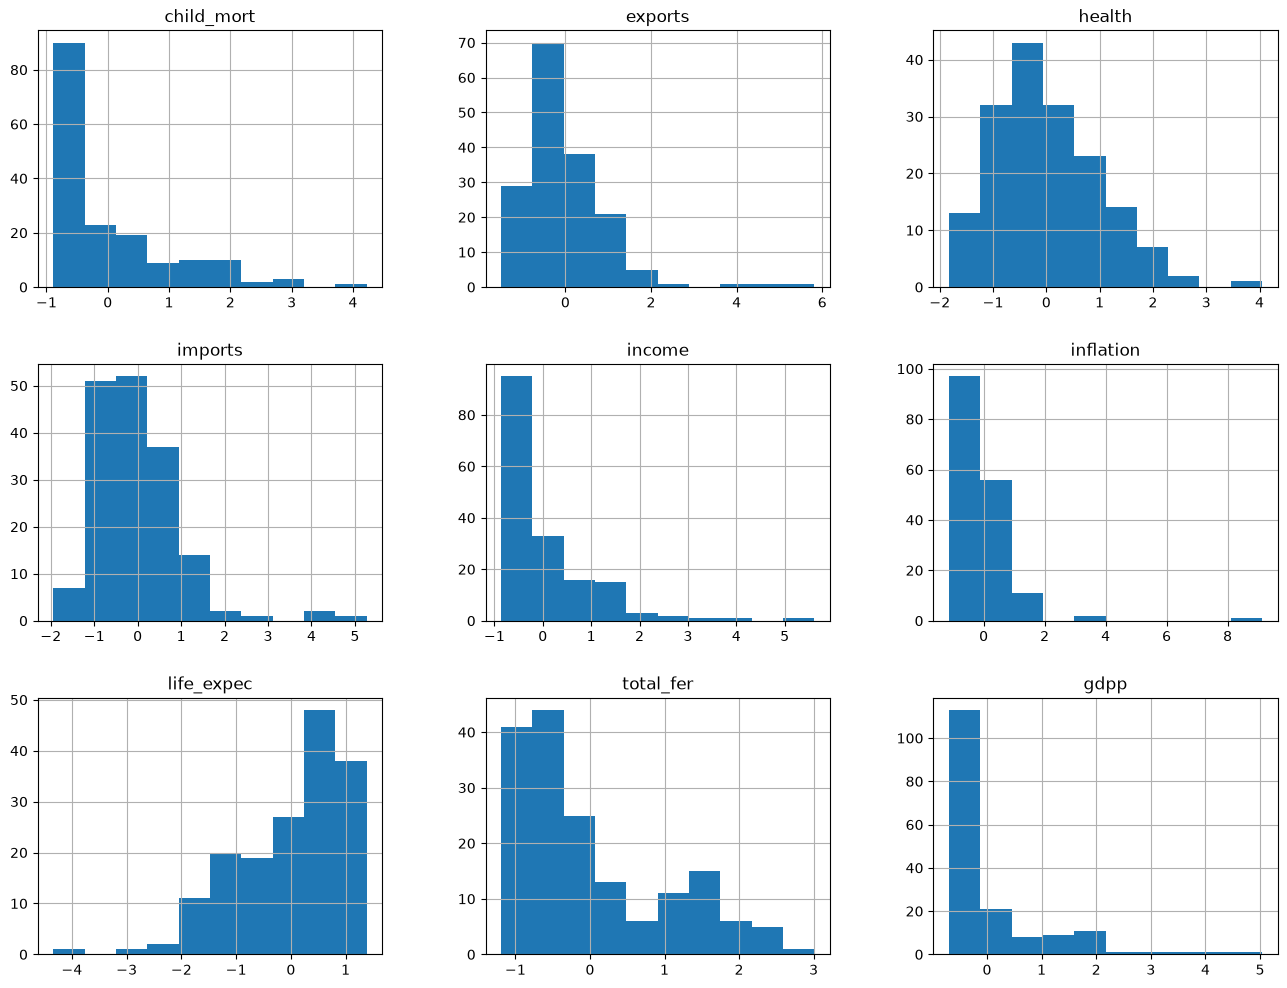

(167, 9) 



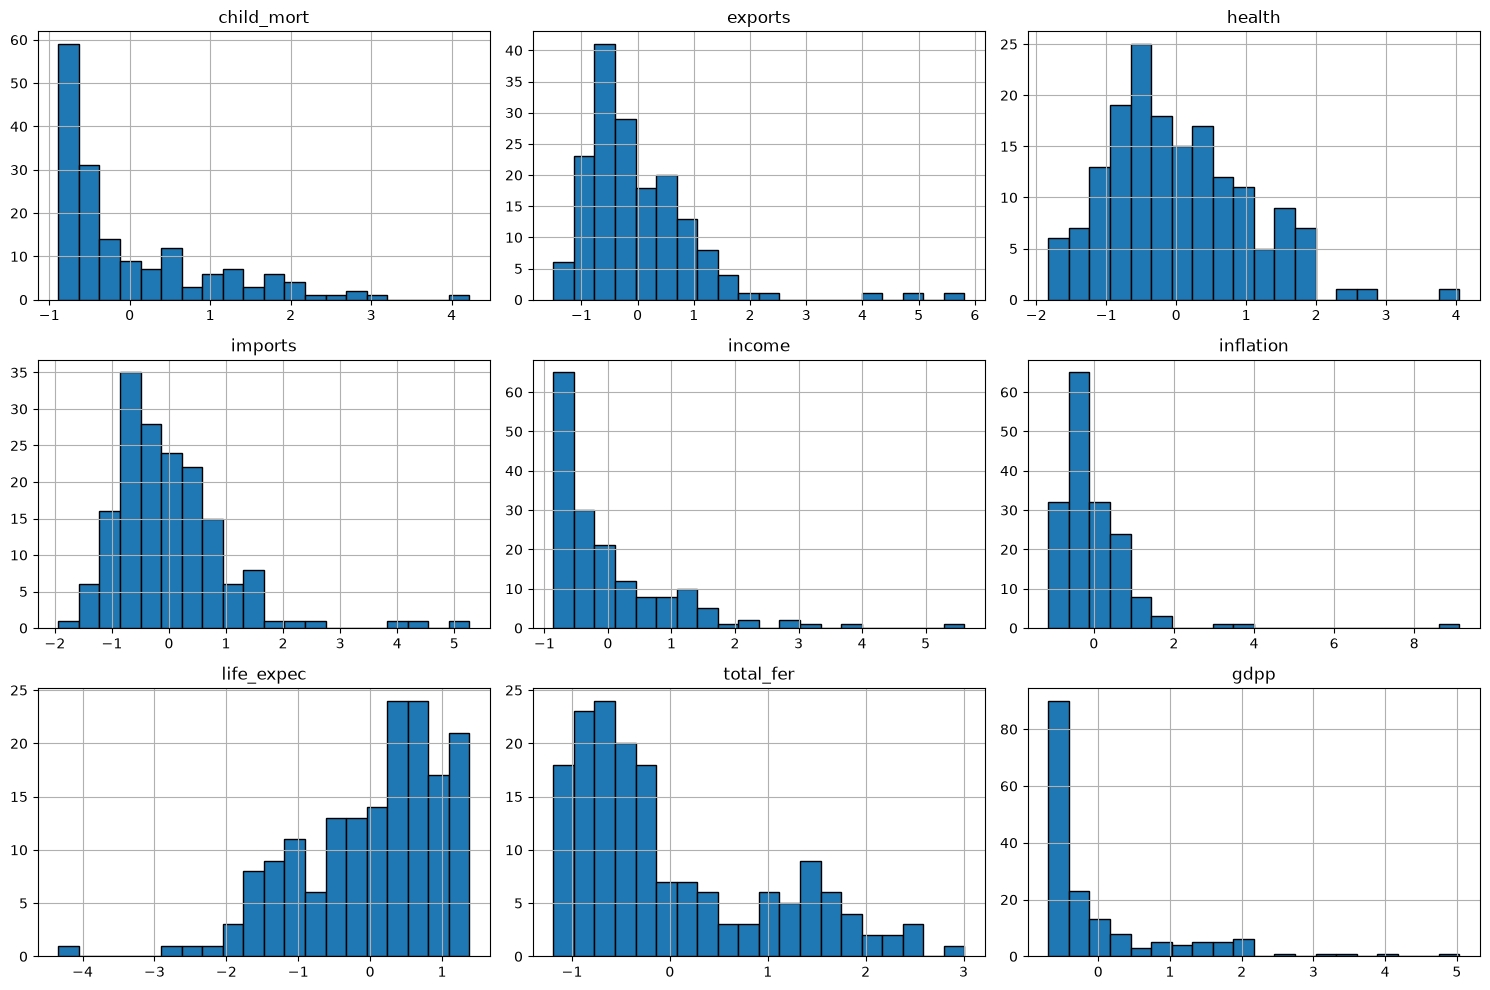

In [18]:
# code here
rcParams['figure.figsize'] = 16,12
plots = df_norm.hist()
plt.show()

print(df_norm.shape,"\n")


import seaborn as sns

# Crear histogramas de todas las características
df_norm.hist(figsize=(15, 10), bins=20, edgecolor='black')

# Ajustar el espacio entre gráficos
plt.tight_layout()

# Mostrar los histogramas
plt.show()

## KMeans


Let's warm up with the well known algorithm named KMeans!

Centroid-based clustering organizes the data into non-hierarchical clusters, contrarily to hierarchical clustering. KMeans is the most widely-used centroid-based clustering algorithm. Centroid-based algorithms are efficient but sensitive to initial conditions and outliers. 


To better understand the way the algorithm works, you can look at the following resources :
* Clustering & K-means (fr): https://www.youtube.com/watch?v=FTtzd31IAOw (up to 11min)
* Clustering & K-means (en): https://www.youtube.com/watch?v=QXOkPvFM6NU  (up to 7min46)
* https://stanford.edu/~cpiech/cs221/handouts/kmeans.html


Then answer the below questions (in your own words):
1. What is a centroid?
2. How can you compute a centroid?
3. Are you supposed to know in advance the number of clusters in order to use the KMeans algorithm?

*Answer here*

***
    Qu’est-ce qu’un centroïde ?
        Un centroïde est le point central d'un cluster. Il représente la position moyenne de tous les points appartenant à ce groupe.
        
    Comment calculer un centroïde ?
        Il se calcule en faisant la moyenne des valeurs de chaque caractéristique de tous les points appartenant au même cluster.

    Êtes-vous censé connaître à l'avance le nombre de clusters afin d'utiliser l'algorithme KMeans?
        Oui. Avant d'appliquer KMeans, nous devons choisir le nombre de clusters (K) que nous voulons obtenir. Nous pouvons utiliser le coefficient de Silhouette pour nous aider à choisir le nombre approprié.

    💡 Para recordar:
        Centroide: centro de un grupo.
        Cálculo: media de los valores de los puntos del grupo.
        KMeans: necesita conocer previamente el número de clusters (K).
***

#### Make the necessary imports from scikit learn in order to perform KMeans clustering

In [19]:
# code here
# # Importar KMeans y aplicar el algoritmo

from sklearn.cluster import KMeans

# # Realizo una copia de mi DataFrame normalizado para no perderlo
df_norm1 = df_norm.copy()

# Crear el modelo KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Aplicar el clustering
kmeans.fit(df_norm1)

# # Obtener los clusters asignados

# Obtener las etiquetas de cada país
clusters = kmeans.labels_

# Añadir los clusters al DataFrame
df_norm1['cluster'] = clusters

# # Verifico los resultados
# Mostrar las primeras 5 filas
print(df_norm1.head())

# # Contar los elementos de cada cluster
print(df_norm1['cluster'].value_counts())



   child_mort   exports    health   imports    income  inflation  life_expec  \
0    1.291532 -1.138280  0.279088 -0.082455 -0.808245   0.157336   -1.619092   
1   -0.538949 -0.479658 -0.097016  0.070837 -0.375369  -0.312347    0.647866   
2   -0.272833 -0.099122 -0.966073 -0.641762 -0.220844   0.789274    0.670423   
3    2.007808  0.775381 -1.448071 -0.165315 -0.585043   1.387054   -1.179234   
4   -0.695634  0.160668 -0.286894  0.497568  0.101732  -0.601749    0.704258   

   total_fer      gdpp  cluster  
0   1.902882 -0.679180        1  
1  -0.859973 -0.485623        2  
2  -0.038404 -0.465376        2  
3   2.128151 -0.516268        1  
4  -0.541946 -0.041817        2  
cluster
2    84
1    47
0    36
Name: count, dtype: int64


c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


#### Exploring KMeans with sklearn

The goal of this step is to become familiar with the sklearn clustering package and the silhouette analysis concepts.

Start by peforming a clustering of the data in *df_norm* into 5 clusters.

In [21]:
# code here
# # KMeans con 5 clusters

# # Realizo una copia de mi DataFrame normalizado para no perderlo
df_norm2 = df_norm.copy()


# df_norm = df_norm.drop(columns=['cluster'], errors='ignore')
# kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
# kmeans.fit(df_norm)
# df_norm['cluster'] = kmeans.labels_
# print(df_norm['cluster'].value_counts())

# Crear el modelo KMeans con 5 clusters
kmeans2 = KMeans(n_clusters=5, random_state=42, n_init=10)
""" 
    KMeans(n_clusters=5):   configura el algoritmo para dividir los datos en 5 grupos.
    random_state=42:        garantiza la reproducibilidad de los resultados.
    n_init=10:              ejecuta el algoritmo 10 veces con diferentes inicializaciones para buscar una buena solución.
    kmeans.fit(df_norm):    entrena el modelo y encuentra los 5 clusters.
    kmeans.labels_:         recupera la etiqueta asignada a cada país.
    value_counts():         muestra cuántos países pertenecen a cada cluster.
"""

# Entrenar el modelo
kmeans2.fit(df_norm2)

# Obtener las etiquetas de los clusters
clusters2 = kmeans2.labels_

# Añadir los clusters al DataFrame
df_norm2['cluster'] = clusters2

# Mostrar los primeros registros
print(df_norm2.head())

# Mostrar el número de elementos en cada cluster
print(df_norm2['cluster'].value_counts())

   child_mort   exports    health   imports    income  inflation  life_expec  \
0    1.291532 -1.138280  0.279088 -0.082455 -0.808245   0.157336   -1.619092   
1   -0.538949 -0.479658 -0.097016  0.070837 -0.375369  -0.312347    0.647866   
2   -0.272833 -0.099122 -0.966073 -0.641762 -0.220844   0.789274    0.670423   
3    2.007808  0.775381 -1.448071 -0.165315 -0.585043   1.387054   -1.179234   
4   -0.695634  0.160668 -0.286894  0.497568  0.101732  -0.601749    0.704258   

   total_fer      gdpp  cluster  
0   1.902882 -0.679180        1  
1  -0.859973 -0.485623        0  
2  -0.038404 -0.465376        0  
3   2.128151 -0.516268        1  
4  -0.541946 -0.041817        0  
cluster
0    84
1    47
3    32
2     3
4     1
Name: count, dtype: int64


c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Print the centroids obtained

In [23]:
# code here

# Imprimir los centroides obtenidos
print("Centroides de los 5 clusters:")
print(kmeans2.cluster_centers_)


# Otra forma de visualizarlos
centroides = pd.DataFrame(
    kmeans2.cluster_centers_,
    columns=df_norm2.drop(columns=['cluster']).columns
)

print(centroides)

Centroides de los 5 clusters:
[[-4.14240255e-01 -4.86342568e-03 -2.36120919e-01  2.60358285e-02
  -2.25991567e-01 -1.54639981e-02  2.76216288e-01 -4.44140566e-01
  -3.49263153e-01]
 [ 1.30629603e+00 -4.18848834e-01 -1.28947379e-01 -1.32964511e-01
  -6.90624629e-01  2.05899480e-01 -1.27930022e+00  1.34238878e+00
  -6.05453328e-01]
 [-8.49003244e-01  4.93567278e+00 -8.16303241e-03  4.54805768e+00
   2.43954240e+00 -5.04206141e-01  1.22682431e+00 -1.03886271e+00
   2.44079735e+00]
 [-8.22940855e-01  1.83308008e-01  8.29894098e-01 -2.61252058e-01
   1.39837771e+00 -4.99856230e-01  1.07433094e+00 -7.68250332e-01
   1.59543611e+00]
 [ 2.28138502e+00 -5.78451631e-01 -6.37438082e-01 -1.22178479e+00
  -6.24064774e-01  9.12971806e+00 -1.13412081e+00  1.91613337e+00
  -5.81936274e-01]]
   child_mort   exports    health   imports    income  inflation  life_expec  \
0   -0.414240 -0.004863 -0.236121  0.026036 -0.225992  -0.015464    0.276216   
1    1.306296 -0.418849 -0.128947 -0.132965 -0.690625 

Print the cluster labels assigned to each point

In [24]:
# code here

# Print Labels 
print("Étiquettes de cluster attribuées à chaque point:")
print(kmeans2.labels_)

# # Mostrar las etiquetas junto a cada registro
"""
    kmeans2.cluster_centers_ → imprime los centroides.
    kmeans2.labels_ → imprime las etiquetas asignadas a cada punto.
    value_counts() → cuenta cuántos puntos hay en cada cluster. 
"""
df_norm2['cluster'] = kmeans2.labels_

print(df_norm2[['cluster']])

# # Número de puntos en cada cluster
print(df_norm2['cluster'].value_counts().sort_index())

Étiquettes de cluster attribuées à chaque point:
[1 0 0 1 0 0 0 3 3 0 3 0 0 0 0 3 0 1 0 0 0 1 0 3 0 1 1 0 1 3 0 1 1 0 0 0 1
 1 1 0 1 0 3 3 3 0 0 0 0 1 1 0 0 3 3 1 1 0 3 1 3 0 0 1 1 0 1 0 3 0 0 0 1 3
 3 3 0 3 0 0 1 1 3 0 1 0 0 1 1 0 0 2 0 1 1 0 0 1 2 1 0 0 0 0 0 0 1 0 1 0 3
 3 1 4 3 0 1 0 0 0 0 0 3 3 0 0 1 0 0 1 0 0 1 2 0 3 1 1 3 3 0 0 1 0 3 3 0 1
 0 1 1 0 0 0 0 1 0 3 3 3 0 0 0 0 0 1 1]
     cluster
0          1
1          0
2          0
3          1
4          0
..       ...
162        0
163        0
164        0
165        1
166        1

[167 rows x 1 columns]
cluster
0    84
1    47
2     3
3    32
4     1
Name: count, dtype: int64


### **Visualization**

Let's try to visualize the created clusters. As it is easier to visualize 2-dimensional data, first run PCA on the data. Then create a scatterplot to visualize the clustered points, each coloured differently depending on the cluster they belong to.

        PC1       PC2  cluster
0 -2.913025  0.095621        1
1  0.429911 -0.588156        0
2 -0.285225 -0.455174        0
3 -2.932423  1.695555        1
4  1.033576  0.136659        0


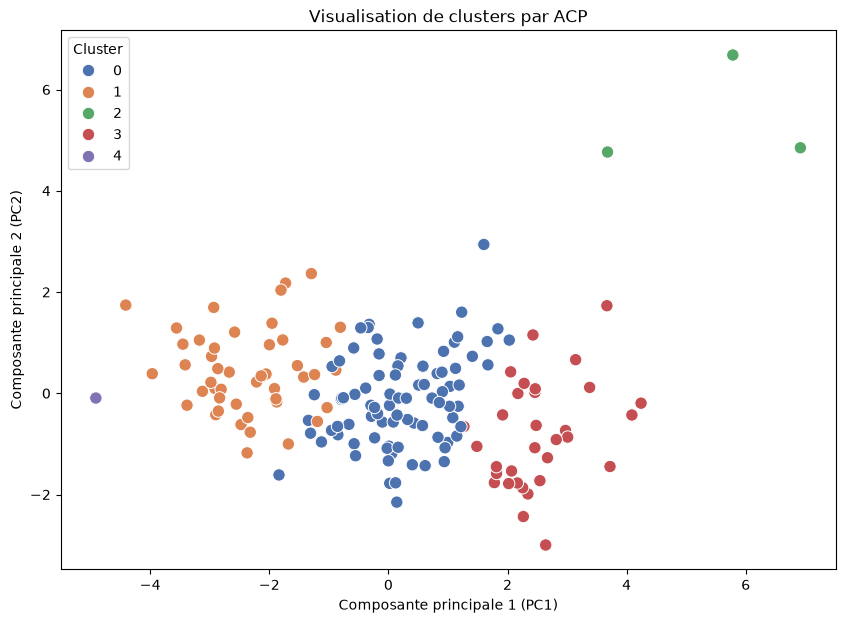

Varianza explicada por cada componente:
[0.4595174  0.17181626]
Varianza total explicada:
0.6313336543771411 

Varianza explicada por cada componente (3 components) :
[0.4595174  0.17181626 0.13004259]
Varianza total explicada 3 components :
0.7613762433466718


In [44]:
# code here
""" 
KMeans ha agrupado los 167 países en 5 clusters.
    Como tengo 9 variables, no puedo representar 
    directamente todos los datos en un gráfico 2D. 
    Por ello se debe utilizar PCA ***(Principal Component Analysis)***, 
    que reduce las dimensiones de los datos a 2 componentes principales.
"""

# # Aplicar PCA para reducir las dimensiones
from sklearn.decomposition import PCA
import seaborn as sns

# Crear PCA con 2 componentes principales
pca = PCA(n_components=2)

# Transformar los datos normalizados
df_pca = pca.fit_transform(df_norm2.drop(columns=['cluster']))

""" 
    n_components=2: queremos reducir las 9 variables a 2 dimensiones.
    fit_transform(): calcula las componentes principales y transforma los datos.
    df_pca: contiene las nuevas coordenadas de los 167 países.
"""

# # Se Crea un DataFrame con los resultados de PCA
df_pca = pd.DataFrame(
    df_pca,
    columns=['PC1', 'PC2']
)

df_pca['cluster'] = clusters2

""" 
    PC1: primera componente principal.
    PC2: segunda componente principal.
    cluster: grupo asignado por KMeans
"""

print(df_pca.head())

# # Creo el gráfico de dispersión (Scatter Plot)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='deep',
    s=80
)

plt.title('Visualisation de clusters par ACP')
plt.xlabel('Composante principale 1 (PC1)')
plt.ylabel('Composante principale 2 (PC2)')
plt.legend(title='Cluster')

plt.show()

""" 
    Cada punto representa un país y cada color representa uno de los cinco clusters.
    Los puntos próximos entre sí tienen características relativamente similares en el espacio PCA.
    Los puntos alejados presentan características más diferentes.
    Los grupos de colores permiten observar cómo KMeans ha realizado la agrupación.
    Si hay colores mezclados, significa que los clusters no están completamente separados en estas dos dimensiones.
"""

# # Extra: comprobar la información explicada por PCA
print("Varianza explicada por cada componente:")
print(pca.explained_variance_ratio_)

print("Varianza total explicada:")
print(pca.explained_variance_ratio_.sum(),"\n")

    # Esto significa que:
    #     PC1 (45,95 %): la primera componente principal conserva casi la mitad de la información (variabilidad) 
    #     de tus 9 variables originales.
    #     PC2 (17,18 %): la segunda componente aporta un 17,18 % adicional.
    #     Total (63,13 %): entre las dos componentes conservas el 63,13 % de la variabilidad original.
    #     Al reducir tus 9 dimensiones a solamente 2, estás perdiendo aproximadamente un 36,87 % de la variabilidad original

pca_3 = PCA(n_components=3)

df_pca_3 = pca_3.fit_transform(
    df_norm2.drop(columns=['cluster'])
)

# # Extra: comprobar la información explicada por PCA
print("Varianza explicada por cada componente (3 components) :")
print(pca_3.explained_variance_ratio_)
print("Varianza total explicada 3 components :")
print(pca_3.explained_variance_ratio_.sum())


In [54]:
sns.color_palette("Paired")

[(0.6509803921568628, 0.807843137254902, 0.8901960784313725),
 (0.12156862745098039, 0.47058823529411764, 0.7058823529411765),
 (0.6980392156862745, 0.8745098039215686, 0.5411764705882353),
 (0.2, 0.6274509803921569, 0.17254901960784313),
 (0.984313725490196, 0.6039215686274509, 0.6),
 (0.8901960784313725, 0.10196078431372549, 0.10980392156862745),
 (0.9921568627450981, 0.7490196078431373, 0.43529411764705883),
 (1.0, 0.4980392156862745, 0.0),
 (0.792156862745098, 0.6980392156862745, 0.8392156862745098),
 (0.41568627450980394, 0.23921568627450981, 0.6039215686274509),
 (1.0, 1.0, 0.6),
 (0.6941176470588235, 0.34901960784313724, 0.1568627450980392)]

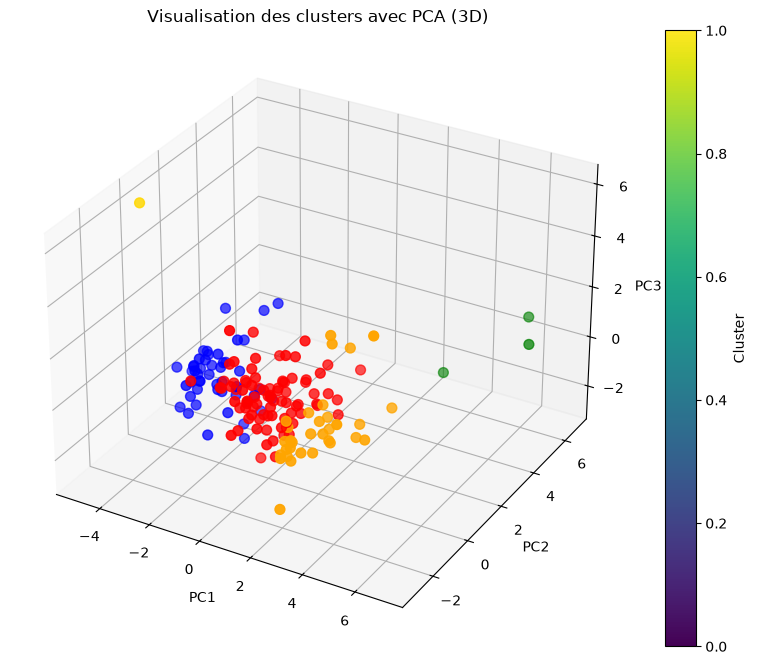

In [63]:
## # Yo inventando
from mpl_toolkits.mplot3d import Axes3D

pca_3 = PCA(n_components=3)

df_pca_3 = pca_3.fit_transform(
    df_norm2.drop(columns=['cluster'])
)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Using a dictionary to highlight a specific category
#custom_map = {"seagreen", "royalblue", "crimson", "gold", "salmon" }
mapa_colores = {
    0: 'red',
    1: 'blue',
    2: 'green',
    3: 'orange',
    4: 'gold'
}

# Creamos una lista de colores correspondiente a cada punto
colores_puntos = [mapa_colores[cluster] for cluster in clusters2]


scatter = ax.scatter(
    df_pca_3[:, 0],
    df_pca_3[:, 1],
    df_pca_3[:, 2],
    #c=clusters2,
    #cmap='viridis',
    c=colores_puntos,
    s=50
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')

ax.set_title('Visualisation des clusters avec PCA (3D)')

plt.colorbar(scatter, label='Cluster')
plt.show()

### Evaluation

**Inertia** can be a measure of how internally coherent clusters are. It represents the within-cluster sum-of-squares.

Read more about it here:
https://scikit-learn.org/stable/modules/clustering.html#k-means 

Print the inertia obtained after the clustering.

In [66]:
# code here
""" 
    Scikit-learn calcula automáticamente la inercia (Inertia) durante el entrenamiento de KMeans.
"""

""" 
 ¿Qué es la inercia?
    La inercia mide la suma de las distancias cuadradas entre cada punto y el centroide del cluster al que pertenece.
    En otras palabras, mide cuánto se parecen entre sí los elementos de cada cluster
"""

# # Imprimir la inercia
inertia = kmeans2.inertia_ 

print("Inertie obtenue après le clustering :")
print(kmeans2.inertia_)

Inertie obtenue après le clustering :
620.1633712888422


**The silhouette score**

Make the necessary imports from scikit learn and compute the silhoutte score.

Read what this score represents and how it is computed here: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html and here https://scikit-learn.org/stable/modules/clustering.html#silhouette-coefficient

In [67]:
# code here
from sklearn.metrics import silhouette_score

""" 
    El Silhouette Score (coeficiente de silueta) nos permite evaluar 
    si los países están bien agrupados dentro de sus clusters y si 
    están suficientemente separados de los demás
"""

# # Calcular el Silhouette Score
# Como ya has entrenado KMeans con 5 clusters, utilizo los modelos entrenados

silhouette_avg = silhouette_score(
    df_norm2.drop(columns=['cluster']),
    kmeans2.labels_
)

print("Silhouette Score:", silhouette_avg)

""" 
    ¿Qué es el Silhouette Score?
        Esta métrica evalúa dos aspectos:
            Cohesión: qué tan cerca está un país de los demás países de su mismo cluster.
            Separación: qué tan lejos está de los países pertenecientes a otros clusters.
        Para cada punto se calculan dos distancias:
            a: distancia media entre un punto y los demás puntos de su propio cluster.
            b: distancia media entre ese punto y los puntos de su cluster vecino más cercano.
    ¿Cómo interpretar el resultado?
        Cercano a 1: Muy buena separación. Los clusters están bien definidos y separados
        Cercano a 0: Clusters solapados. Hay países que se encuentran cerca de las fronteras entre clusters
        Negativo : Posible mala asignación. Algunos países podrían estar mejor situados en otro cluster
"""



Silhouette Score: 0.2992594995920442


' \n    ¿Qué es el Silhouette Score?\n        Esta métrica evalúa dos aspectos:\n            Cohesión: qué tan cerca está un país de los demás países de su mismo cluster.\n            Separación: qué tan lejos está de los países pertenecientes a otros clusters.\n        Para cada punto se calculan dos distancias:\n            a: distancia media entre un punto y los demás puntos de su propio cluster.\n            b: distancia media entre ese punto y los puntos de su cluster vecino más cercano.\n    ¿Cómo interpretar el resultado?\n        Cercano a 1: Muy buena separación. Los clusters están bien definidos y separados\n        Cercano a 0: Clusters solapados. Hay países que se encuentran cerca de las fronteras entre clusters\n        Negativo : Posible mala asignación. Algunos países podrían estar mejor situados en otro cluster\n'

You can read more about other clustering evaluation methods here: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation

#### Finding the number of clusters

In the following article you will find [methods](https://en.wikipedia.org/wiki/Determining_the_number_of_clusters_in_a_data_set) for determining the optimal number of clusters.

The first step for using this algorithm is to use the silhouette analysis technique for obtaining the number of clusters.

(another method you can try is the [elbow method](https://en.wikipedia.org/wiki/Elbow_method_(clustering)) but this is not very reliable)

- Use the silhouette analysis to find an optimal number of clusters

<u><i>Hint:</u></i> Feel free to use the `n_jobs` hyperparameter to speed up your computation

c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\clust

Clusters: 2 | Silhouette Score: 0.2874
Clusters: 3 | Silhouette Score: 0.2833
Clusters: 4 | Silhouette Score: 0.2960
Clusters: 5 | Silhouette Score: 0.2993
Clusters: 6 | Silhouette Score: 0.2287


c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\clust

Clusters: 7 | Silhouette Score: 0.2477
Clusters: 8 | Silhouette Score: 0.2388
Clusters: 9 | Silhouette Score: 0.2073
Clusters: 10 | Silhouette Score: 0.2022


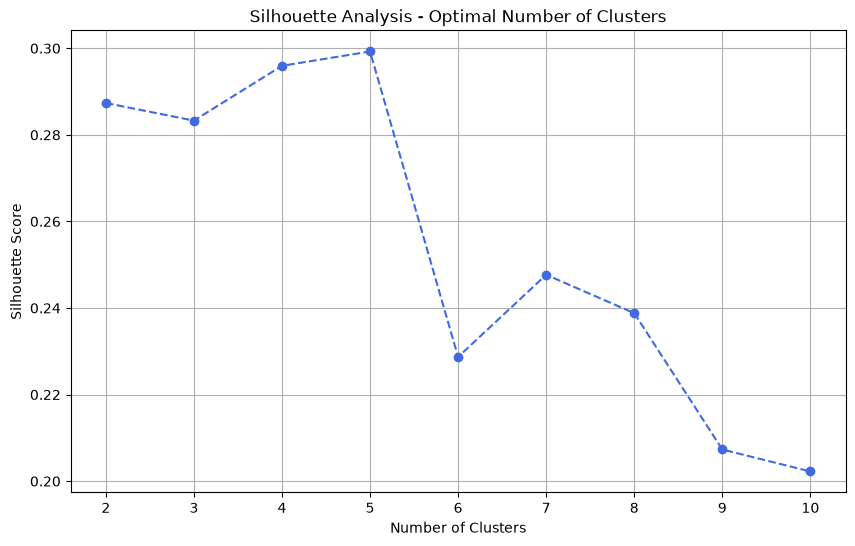

Número óptimo de clusters: 5
Mejor Silhouette Score: 0.2992594995920442
cluster
0    84
1    47
2     3
3    32
4     1
Name: count, dtype: int64


c:\Users\Robert\anaconda3\envs\ML-clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [ ]:
# code here
import numpy as np
# # encontrar el número óptimo de clusters utilizando el análisis de silueta (Silhouette Analysis)

# Utilizar únicamente las variables originales normalizadas
X = df_norm2.drop(columns=['cluster'], errors='ignore')

silhouette_scores = []

# Probar entre 2 y 10 clusters
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        metric='euclidean',
        n_jobs=-1
    )
    # ¿Qué hace n_jobs=-1?
    # Intenta utilizar todos los procesadores disponibles para acelerar el cálculo de las distancias.

    silhouette_scores.append(score)

    print(f'Clusters: {k} | Silhouette Score: {score:.4f}')


# Representar los resultados gráficamente
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o',
    linestyle='--',
    color='royalblue'
)

plt.title('Silhouette Analysis - Optimal Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()


# # Identificar automáticamente el mejor número de clusters
# best_k = range(2, 11)
best_k = int(np.argmax(silhouette_scores) + 2)

# print("Número óptimo de clusters:", best_k)
# print("Mejor Silhouette Score:", max(silhouette_scores))
[silhouette_scores.index(max(silhouette_scores))]

print("Número óptimo de clusters:", best_k)
print("Mejor Silhouette Score:", max(silhouette_scores))


# # Entrenar el modelo definitivo
kmeans_optimal = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters_optimal = kmeans_optimal.fit_predict(X)

df_norm2['cluster'] = clusters_optimal

""" 
    Una precisión importante: el valor máximo del Silhouette Score es 
    nuestro principal criterio de selección, pero no siempre representa 
    automáticamente la mejor segmentación desde el punto de vista práctico.
"""

print(df_norm2['cluster'].value_counts().sort_index())

#### Preprocessing and model testing

Try different preprocessing methods of the data (StandardScaler, MinMaxScaler, ...) (and if you want, different clustering models (KMeans, SpectralClustering,...), and plot again PCA and TSNE to pick the combination that gives a better silhouette score, plot and separation of the clusters on the plots :

In [ ]:
# code here

What is the optimal number of clusters that you obtained?

*Answer here*

## Hierarchical Clustering

Let's try to apply now a different method on the same data. You can find more explanations on hierarchical clustering in the following links :
 * https://www.youtube.com/watch?v=QXOkPvFM6NU&t=1s (from minute 11:34 onwards)
 * https://stackabuse.com/hierarchical-clustering-with-python-and-scikit-learn/ (example on how to do hierarchical clustering with scikit-learn)
 * https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering

Make the necessary imports from scikit learn to perform hierarchical clustering. 

Start by plotting the dendrogram and deciding the number of clusters. Then apply hierarchical clustering.

You might find this useful: https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html for creating the dendrogram.

In [ ]:
# code here

How many clusters did you find?

*Answer here*

Compare the kmeans labels with the labels obtained by the hierarchical clustering.

In [ ]:
# code here

### Application: clustering images

Theses techniques can be use to reduce the number of colours in a picture

- find a picture you want to reduce the number of colours.
- use `skimages` and `sklearn` to reduce the number of colours in this picture
- from your picture create two pictures with 16 colours what do you notice?

In [ ]:
# install skimage

#Code here

Now let's try to apply KMeans clustering on the simple digits data that can be loaded from sklearn (https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)

The goal is to use KMeans to try to identify similar digits without using the original label information.

Start by loading the digits and then finding the KMeans clusters. The digits data consists of 1,797 samples with 64 features, where each of the 64 features is the brightness of one pixel in an 8×8 image.

In [ ]:
# code here

The cluster centroids themselves are 64-dimensional points, and can thus be interpreted as the "typical" digit within the cluster. Plot each cluster center. Hint: use *imshow*

In [ ]:
# code here

For each of the data points we also have access to their real labels (using *digits.target*). This means we can verify if the clustering algorithm split the data in such a way as to predict the original classes. 

Note that the labels of the discovered clusters may not directly match the initial labels in the dataset (they could be permuted). Write code to match each learned cluster label with the true labels of the data found in them.

In [ ]:
# code here

Now compute the accuracy score between the true labels from the data and the predicted ones.

In [ ]:
# code here

Plot the confusion matrix between the predicted labels and the actual labels. Which were the digits that were most often confused with other digits?

In [ ]:
# code here

What if instead of keeping the original 64 features, we perform a projection into 2 dimensions?
Use the t-distributed stochastic neighbor embedding (t-SNE) algorithm to pre-process the data before performing KMeans. t-SNE is a nonlinear embedding algorithm that is particularly adept at preserving points within clusters.

Compute the new accuracy.

In [ ]:
# code here